# Лабораторна робота № 1. Апроксимація та інтерполяція функцій

**Варіант 23.** Курс «Основи цифрової обробки сигналів», Серафін Д.А., ІР-43.

## Вихідні дані варіанту

Пари вимірювань xₙ, yₙ з таблиці «Завдання 1»: N = 8, крок hₙ = 0,1. NumPy, SciPy і matplotlib у Colab вже встановлені, тому нічого доставляти не потрібно.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import CubicSpline

sample_x = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8])
sample_y = np.array([1, 2, 2, 3, 3, 4, 4, 5], dtype=float)
sample_count = len(sample_x)


def clean(value):
    """Round away float noise, so a tiny negative number prints as 0.000000, not -0.000000."""
    return np.round(value, 10) + 0.0


print(f"Variant 23, N = {sample_count}")
print("x_n:", sample_x)
print("y_n:", sample_y)

Variant 23, N = 8
x_n: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8]
y_n: [1. 2. 2. 3. 3. 4. 4. 5.]


## 1. Апроксимуючий поліном P(x) = a + bx + cx², ручний розрахунок

Шукаємо коефіцієнти, при яких S = Σ(P(xₙ) − yₙ)² (вираз 6) найменша. Після прирівнювання частинних похідних до нуля виходить нормальна система (10). Її розв’язуємо методом Крамера: a = Δa/Δ, b = Δb/Δ, c = Δc/Δ.

In [2]:
# Sums that make up the normal equations (10).
sum_x = np.sum(sample_x)
sum_x2 = np.sum(sample_x**2)
sum_x3 = np.sum(sample_x**3)
sum_x4 = np.sum(sample_x**4)
sum_y = np.sum(sample_y)
sum_xy = np.sum(sample_x * sample_y)
sum_x2y = np.sum(sample_x**2 * sample_y)

normal_matrix = np.array([
    [sample_count, sum_x, sum_x2],
    [sum_x, sum_x2, sum_x3],
    [sum_x2, sum_x3, sum_x4],
])
right_hand_side = np.array([sum_y, sum_xy, sum_x2y])

# Cramer's rule: replace one column with the right-hand side and divide its determinant by the main one.
main_determinant = np.linalg.det(normal_matrix)
column_determinants = []
for column_index in range(3):
    replaced_matrix = normal_matrix.copy()
    replaced_matrix[:, column_index] = right_hand_side
    column_determinants.append(np.linalg.det(replaced_matrix))
polynomial_coefficients = np.array(column_determinants) / main_determinant
constant_term, linear_term, quadratic_term = polynomial_coefficients


def evaluate_polynomial(x_values):
    """Value of P(x) = a + b * x + c * x^2 from formula (4)."""
    return constant_term + linear_term * x_values + quadratic_term * x_values**2


fitted_values = evaluate_polynomial(sample_x)
residual_sum_of_squares = np.sum((fitted_values - sample_y) ** 2)  # formula (6)
polynomial_text = f"{clean(constant_term):.6f} + {clean(linear_term):.6f}x + {clean(quadratic_term):.6f}x²"

print(f"Sum x = {sum_x:.4f}, sum x^2 = {sum_x2:.4f}, sum x^3 = {sum_x3:.4f}, sum x^4 = {sum_x4:.4f}")
print(f"Sum y = {sum_y:.4f}, sum xy = {sum_xy:.4f}, sum x^2 y = {sum_x2y:.4f}")
print("Normal equations (10):")
print(normal_matrix, "|", right_hand_side)
print(f"Determinants: main = {clean(main_determinant):.6f}, a = {clean(column_determinants[0]):.6f}, "
      f"b = {clean(column_determinants[1]):.6f}, c = {clean(column_determinants[2]):.6f}")
print(f"a = {clean(constant_term):.6f}, b = {clean(linear_term):.6f}, c = {clean(quadratic_term):.6f}")
print(f"P(x) = {polynomial_text}")
print("P(x_n):", np.round(fitted_values, 6))
print(f"Residual sum of squares S = {residual_sum_of_squares:.6f}")

Sum x = 3.6000, sum x^2 = 2.0400, sum x^3 = 1.2960, sum x^4 = 0.8772
Sum y = 24.0000, sum xy = 13.0000, sum x^2 y = 8.1000
Normal equations (10):
[[8.     3.6    2.04  ]
 [3.6    2.04   1.296 ]
 [2.04   1.296  0.8772]] | [24.  13.   8.1]
Determinants: main = 0.056448, a = 0.036288, b = 0.295680, c = 0.000000
a = 0.642857, b = 5.238095, c = 0.000000
P(x) = 0.642857 + 5.238095x + 0.000000x²
P(x_n): [1.166667 1.690476 2.214286 2.738095 3.261905 3.785714 4.309524 4.833333]
Residual sum of squares S = 0.476190


## 1. Перевірка функцією `np.polyfit`

`np.polyfit(x, y, 2)` будує той самий поліном методом найменших квадратів. Порівнюємо коефіцієнти з ручним розрахунком.

In [3]:
# np.polyfit returns the highest power first, so the order is flipped to a, b, c.
library_polynomial_coefficients = np.polyfit(sample_x, sample_y, 2)[::-1]
polynomial_difference = np.max(np.abs(polynomial_coefficients - library_polynomial_coefficients))
print("np.polyfit: a, b, c =", np.round(clean(library_polynomial_coefficients), 6))
for name, hand_value, library_value in zip("abc", polynomial_coefficients, library_polynomial_coefficients):
    print(f"|hand - polyfit| for {name} = {abs(hand_value - library_value):.1e}")
print(f"max |hand - polyfit| = {polynomial_difference:.1e}")

np.polyfit: a, b, c = [0.642857 5.238095 0.      ]
|hand - polyfit| for a = 6.7e-16
|hand - polyfit| for b = 3.6e-14
|hand - polyfit| for c = 3.7e-14
max |hand - polyfit| = 3.7e-14


## 2. Звичайний кубічний сплайн, ручний розрахунок

На кожному інтервалі Pₙ(x) = aₙ + bₙ(x − xₙ) + cₙ(x − xₙ)² + dₙ(x − xₙ)³ (вираз 12), де hₙ = xₙ₊₁ − xₙ. Сплайн звичайний, тому на кінцях y″₁ = y″₈ = 0. Другі похідні у внутрішніх точках знаходимо з тридіагональної системи (26), а коефіцієнти рахуємо за виразами (20)–(23).

In [4]:
steps = np.diff(sample_x)  # h_n = x_(n+1) - x_n
inner_count = sample_count - 2

# Tridiagonal system (26): one row per inner point links its second derivative with the two neighbours.
spline_matrix = np.zeros((inner_count, inner_count))
spline_right_hand_side = np.zeros(inner_count)
for row_index in range(inner_count):
    point_index = row_index + 1
    left_step = steps[point_index - 1]
    right_step = steps[point_index]
    if row_index > 0:
        spline_matrix[row_index, row_index - 1] = left_step
    spline_matrix[row_index, row_index] = 2 * (left_step + right_step)
    if row_index < inner_count - 1:
        spline_matrix[row_index, row_index + 1] = right_step
    spline_right_hand_side[row_index] = 6 * (
        (sample_y[point_index + 1] - sample_y[point_index]) / right_step
        - (sample_y[point_index] - sample_y[point_index - 1]) / left_step
    )

# Natural spline: the second derivative is zero at the first and the last point.
second_derivatives = np.zeros(sample_count)
second_derivatives[1:-1] = np.linalg.solve(spline_matrix, spline_right_hand_side)

# Coefficients of every piece, formulas (20)-(23).
spline_a = sample_y[:-1].copy()
spline_b = np.diff(sample_y) / steps - steps * (second_derivatives[1:] + 2 * second_derivatives[:-1]) / 6
spline_c = second_derivatives[:-1] / 2
spline_d = np.diff(second_derivatives) / (6 * steps)


def evaluate_hand_spline(x_values):
    """Find the interval of every x and use the cubic piece (12) of that interval."""
    interval_indices = np.clip(np.searchsorted(sample_x, x_values, side="right") - 1, 0, sample_count - 2)
    offsets = x_values - sample_x[interval_indices]
    return (spline_a[interval_indices] + spline_b[interval_indices] * offsets
            + spline_c[interval_indices] * offsets**2 + spline_d[interval_indices] * offsets**3)


print("Steps h_n:", np.round(steps, 6))
print("System (26):")
print(spline_matrix, "|", np.round(spline_right_hand_side, 6))
print("Second derivatives y'':", np.round(clean(second_derivatives), 6))
print(f"{'interval':>12} {'a_n':>10} {'b_n':>12} {'c_n':>14} {'d_n':>14}")
for interval_index in range(sample_count - 1):
    print(f"[{sample_x[interval_index]:.1f}; {sample_x[interval_index + 1]:.1f}]"
          f" {spline_a[interval_index]:10.6f} {spline_b[interval_index]:12.6f}"
          f" {clean(spline_c[interval_index]):14.6f} {spline_d[interval_index]:14.6f}")

Steps h_n: [0.1 0.1 0.1 0.1 0.1 0.1 0.1]
System (26):
[[0.4 0.1 0.  0.  0.  0. ]
 [0.1 0.4 0.1 0.  0.  0. ]
 [0.  0.1 0.4 0.1 0.  0. ]
 [0.  0.  0.1 0.4 0.1 0. ]
 [0.  0.  0.  0.1 0.4 0.1]
 [0.  0.  0.  0.  0.1 0.4]] | [-60.  60. -60.  60. -60.  60.]
Second derivatives y'': [   0.       -219.512195  278.04878  -292.682927  292.682927 -278.04878
  219.512195    0.      ]
    interval        a_n          b_n            c_n            d_n
[0.1; 0.2]   1.000000    13.658537       0.000000    -365.853659
[0.2; 0.3]   2.000000     2.682927    -109.756098     829.268293
[0.3; 0.4]   2.000000     5.609756     139.024390    -951.219512
[0.4; 0.5]   3.000000     4.878049    -146.341463     975.609756
[0.5; 0.6]   3.000000     4.878049     146.341463    -951.219512
[0.6; 0.7]   4.000000     5.609756    -139.024390     829.268293
[0.7; 0.8]   4.000000     2.682927     109.756098    -365.853659


## 2. Перевірка функцією `CubicSpline`

`scipy.interpolate.CubicSpline(x, y, bc_type="natural")` будує звичайний сплайн з такими ж крайовими умовами. Порівнюємо другі похідні, коефіцієнти та значення на густій сітці.

In [5]:
library_spline = CubicSpline(sample_x, sample_y, bc_type="natural")
# CubicSpline.c keeps the cubic term in row 0, so the rows are reversed to get a, b, c, d.
library_spline_coefficients = library_spline.c[::-1]
hand_spline_coefficients = np.array([spline_a, spline_b, spline_c, spline_d])
dense_x = np.linspace(sample_x[0], sample_x[-1], 500)

second_derivative_difference = np.max(np.abs(second_derivatives - library_spline(sample_x, 2)))
spline_coefficient_difference = np.max(np.abs(hand_spline_coefficients - library_spline_coefficients))
spline_curve_difference = np.max(np.abs(evaluate_hand_spline(dense_x) - library_spline(dense_x)))
node_error = np.max(np.abs(evaluate_hand_spline(sample_x) - sample_y))
print(f"|hand - CubicSpline| for y''_4 = {abs(second_derivatives[3] - library_spline(sample_x[3], 2)):.1e}")
print(f"|hand - CubicSpline| for d_4 = {abs(spline_d[3] - library_spline_coefficients[3][3]):.1e}")
print(f"max |hand - CubicSpline| for y'' = {second_derivative_difference:.1e}")
print(f"max |hand - CubicSpline| for a, b, c, d = {spline_coefficient_difference:.1e}")
print(f"max |hand - CubicSpline| along the curve = {spline_curve_difference:.1e}")
print(f"max |spline(x_n) - y_n| = {node_error:.1e}")

|hand - CubicSpline| for y''_4 = 5.7e-14
|hand - CubicSpline| for d_4 = 2.3e-13
max |hand - CubicSpline| for y'' = 5.7e-14
max |hand - CubicSpline| for a, b, c, d = 2.8e-13
max |hand - CubicSpline| along the curve = 1.8e-15
max |spline(x_n) - y_n| = 0.0e+00


## 3. Графік функції, апроксимуючого полінома та сплайну

Червоні точки це вихідні дані, синя пунктирна лінія поліном, зелена суцільна сплайн. Рисунок також зберігається у папку `figures/` (180 dpi).

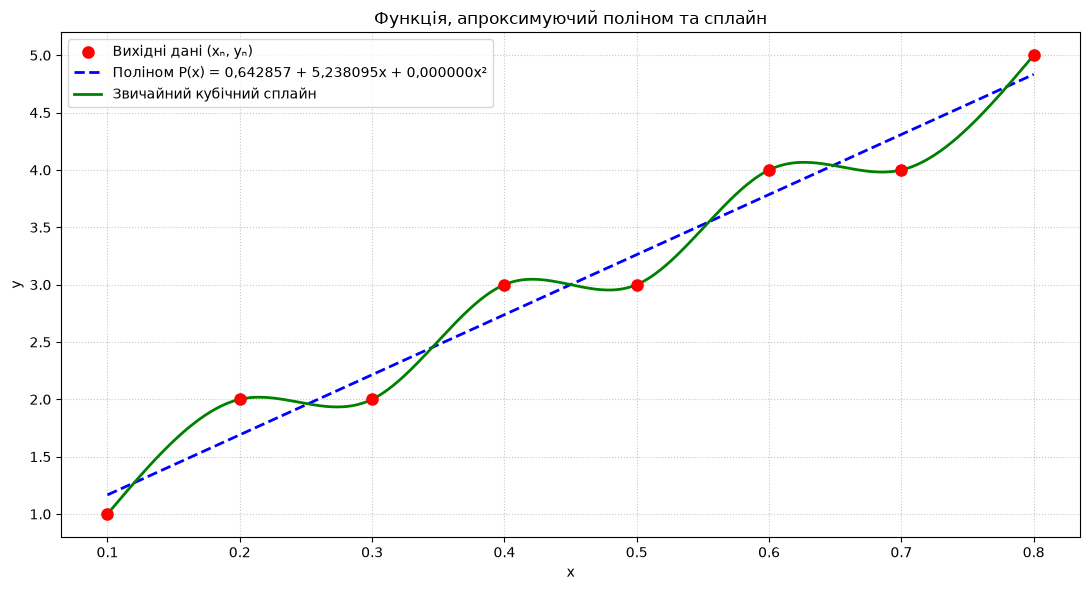

In [6]:
plt.figure(figsize=(11, 6))
plt.scatter(sample_x, sample_y, color="red", s=65, zorder=5, label="Вихідні дані (xₙ, yₙ)")
plt.plot(dense_x, evaluate_polynomial(dense_x), "--", color="blue", linewidth=2,
         label=f"Поліном P(x) = {polynomial_text}".replace(".", ","))
plt.plot(dense_x, evaluate_hand_spline(dense_x), color="green", linewidth=2, label="Звичайний кубічний сплайн")
plt.title("Функція, апроксимуючий поліном та сплайн")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(linestyle=":", alpha=0.7)
plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/function_polynomial_spline.png", dpi=180)
plt.show()

## Підсумок

Коефіцієнти полінома відрізняються від `np.polyfit` менше ніж на 10⁻¹³, коефіцієнти сплайну від `CubicSpline` менше ніж на 10⁻¹². Такі різниці дає лише округлення чисел з плаваючою комою, тому їхні точні значення можуть трохи відрізнятися між запусками на різних комп’ютерах. Сплайн проходить через усі вісім точок.

In [7]:
largest_difference = max(polynomial_difference, second_derivative_difference,
                         spline_coefficient_difference, spline_curve_difference)
print(f"P(x) = {polynomial_text}")
print(f"Largest |hand - library| difference: {largest_difference:.1e}")
print(f"Spline passes through all samples: max error {node_error:.1e}")

P(x) = 0.642857 + 5.238095x + 0.000000x²
Largest |hand - library| difference: 2.8e-13
Spline passes through all samples: max error 0.0e+00
